# Generate a hierarchical parcellation

In this tutorial, we will generate parcellations of any desired scale via the algorithm from [Pang
*et al.* (2025)](doi.org/10.1101/2025.01.30.635820), where the surface or volume mesh of interest is
repeatedly subdivided according to the second (first non-constant) Laplace-Beltrami eigenmode.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from brainspace.mesh.mesh_creation import build_polydata
from nsbutils.plotting import plot_surf
from nsbutils.utils import unparcellate

from neuromodes import EigenSolver
from neuromodes.io import fetch_example_map, fetch_example_surf
from neuromodes.stats import cdistw


In [2]:
# Setup: choose number(s) of parcels to generate
n_parcels = np.arange(500+1, step=10)
n_parcels[0] = 2
view_inds = [1, 5, 10, 50]
labels = [f"{n} parcels" for n in n_parcels[view_inds]]
seed = 0

In [3]:
# Load example surface into solver
surf, medmask = fetch_example_surf()
solver = EigenSolver(surf, medmask)

In [5]:
# Generate all scales of parcellations, outputting each as a column
parcellations = solver.make_parcellation(n_parcels, seed=seed)
parcellations

array([[  1,   8,   9, ..., 125, 125, 125],
       [  2,   2,  15, ..., 275, 275, 275],
       [  2,   2,  12, ..., 124, 124, 124],
       ...,
       [  1,   3,   6, ..., 102, 102,  25],
       [  1,   3,   6, ..., 102, 102,  25],
       [  1,   3,   6, ..., 102, 102,  25]], shape=(29696, 51))

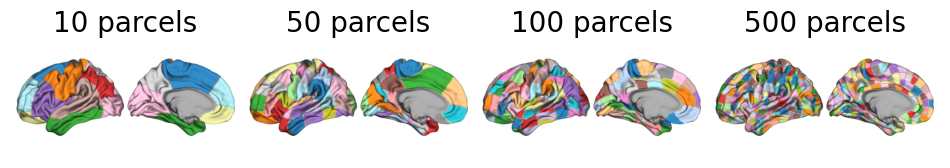

In [6]:
# Plot a few scales of parcellations
plot_surf(
    build_polydata(surf.v, surf.t),
    solver.unmask_data(parcellations[:, view_inds]),
    cmap="tab20",
    cbar=False,
    labels=labels
    )

Now we can showcase how a few of the parcellations work on an example map via `parcellate()`,
including reconstruction accuracy.

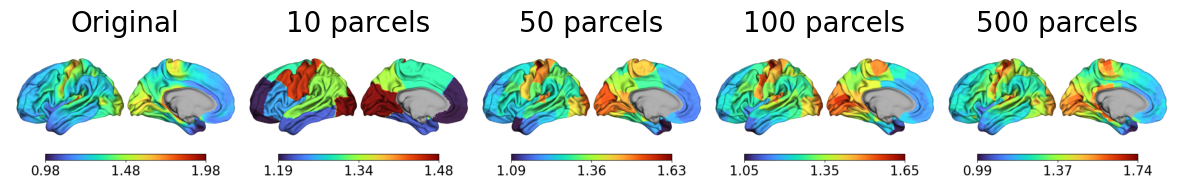

In [ ]:
# Load and parcellate myelin map
myelinmap = fetch_example_map('myelinmap')[medmask]
myelinmap_parc = [solver.parcellate(myelinmap, parcellations[:, j], method="mean") for j in range(len(n_parcels))]

# Reconstruct (unparcellate) the parcellated myelin map to n_verts-length vector for each scale
recon_parc = np.stack(
    [unparcellate(myelinmap_parc[j], parcellations[:, j]) for j in range(len(n_parcels))],
    axis=1)

plot_surf(
    build_polydata(surf.v, surf.t),
    solver.unmask_data(np.concatenate([myelinmap[:, None], recon_parc[:, view_inds]], axis=1)),
    cmap="turbo",
    cbar=True,
    labels=["Original"] + labels
)

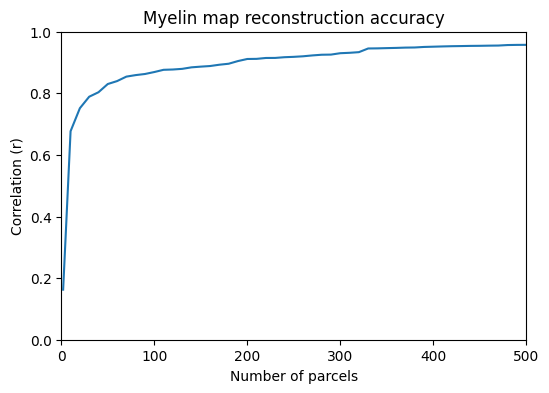

In [10]:
# Correlate each reconstructed myelin map with the original (mass-weighted)
corr_parc = 1-cdistw(myelinmap, recon_parc, metric="correlation", mass=solver.mass)[0]
plt.figure(figsize=(6, 4))
plt.plot(n_parcels, corr_parc)
plt.xlabel("Number of parcels")
plt.ylabel("Correlation (r)")
plt.title("Myelin map reconstruction accuracy")
plt.xlim(0, n_parcels[-1])
plt.ylim(0, 1)
plt.show()

We can also compare the reconstruction accuracy to that of the Laplace-Beltrami eigenmodes directly,
across other maps.

In [11]:
# Compute modes if not computed yet
if solver._emodes is None:
    solver.solve(n_parcels.max())

500 parcels: r=0.976, 500 modes: r=0.995 (fcgradient1)
500 parcels: r=0.944, 500 modes: r=0.978 (thickness)
500 parcels: r=0.958, 500 modes: r=0.986 (ndi)
500 parcels: r=0.952, 500 modes: r=0.986 (odi)


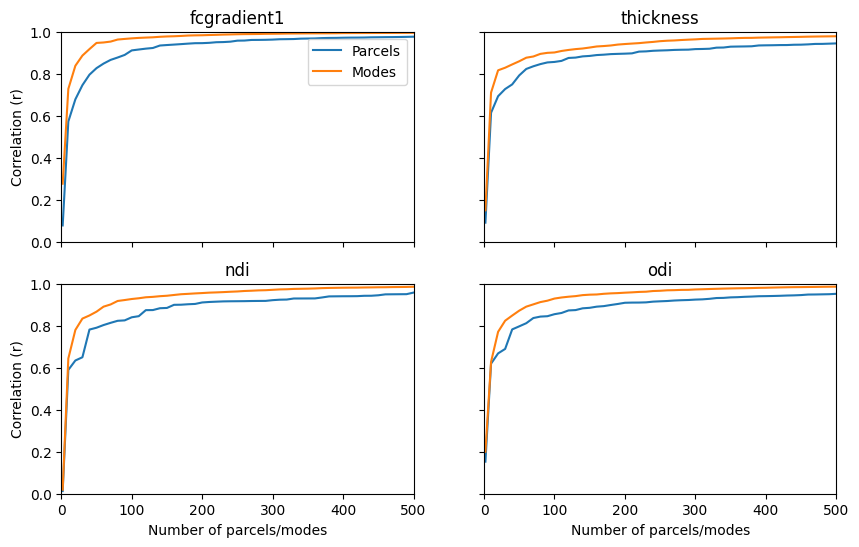

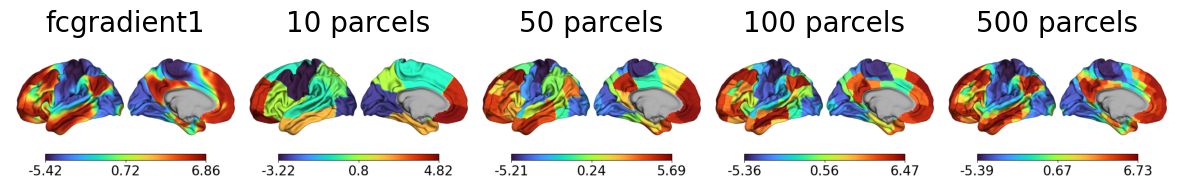

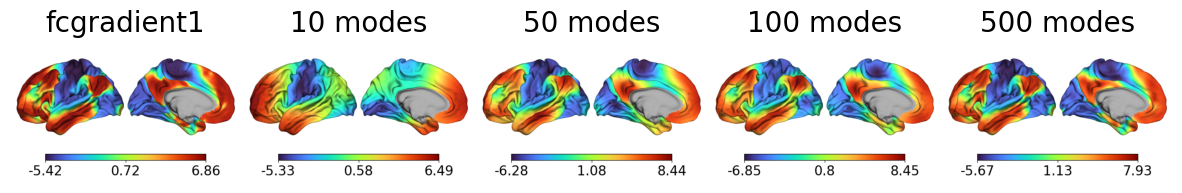

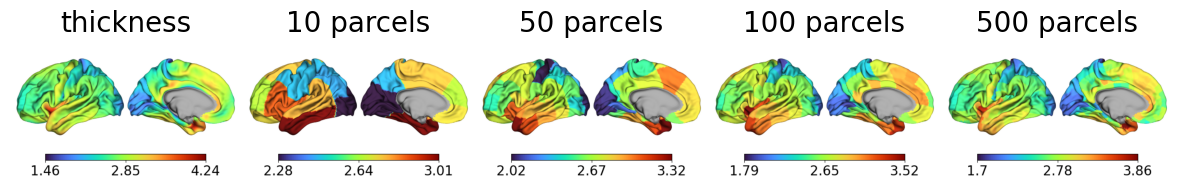

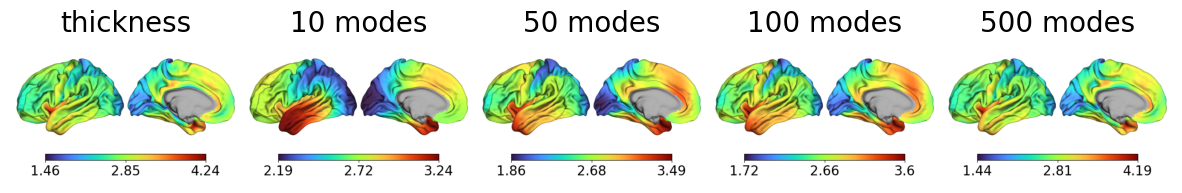

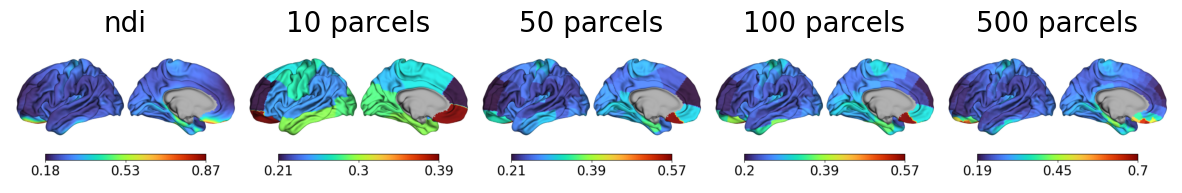

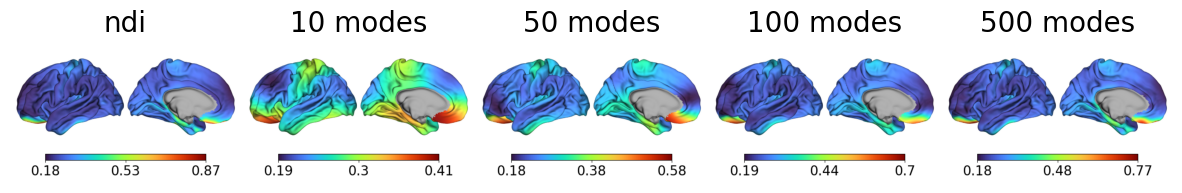

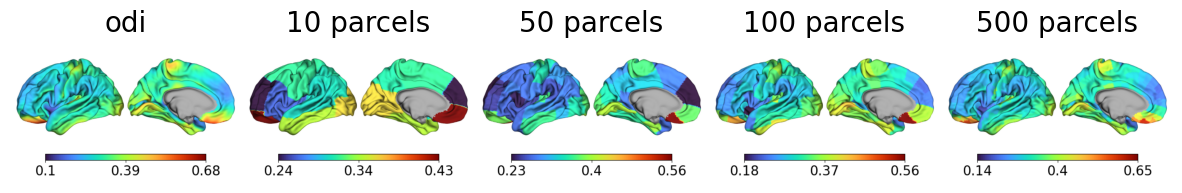

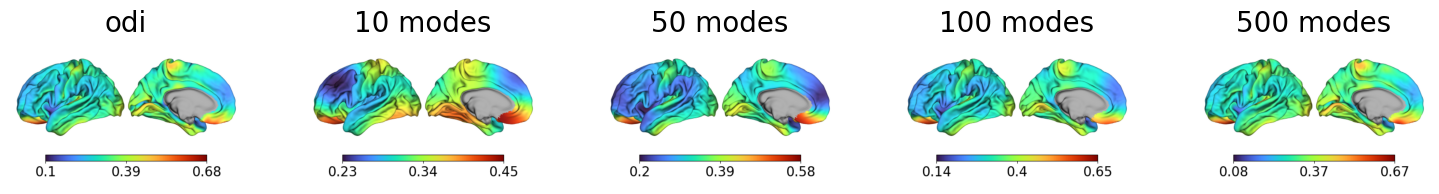

In [ ]:
# Run reconstruction analysis for a few example maps across all 51 scales of parcellation and modes
metric = "correlation"
map_names = ["fcgradient1", "thickness", "ndi", "odi"]
axs = plt.subplots(2, 2, figsize=(10, 6))[1].flatten()

for i, map_name in enumerate(map_names):
    map = fetch_example_map(map_name)[medmask][:, None]
    
    recon_parc = [solver.parcellate(map, parcellations[:, j], method="mean") for j in range(len(n_parcels))]
    recon_parc = np.stack(
        [unparcellate(recon_parc[j], parcellations[:, j]) for j in range(len(n_parcels))],
        axis=1)
        
    plot_surf(
        build_polydata(surf.v, surf.t),
        solver.unmask_data(np.concatenate([map, recon_parc[:, view_inds]], axis=1)),
        cmap="turbo",
        cbar=True,
        labels=[map_name] + labels
    )

    recon_modes = solver.reconstruct(map[:, 0], mode_counts=n_parcels)

    plot_surf(
        build_polydata(surf.v, surf.t),
        solver.unmask_data(np.concatenate([map, recon_modes[:, view_inds]], axis=1)),
        cmap="turbo",
        cbar=True,
        labels=[map_name] + [f"{n} modes" for n in n_parcels[view_inds]]
    )

    corr_parc = 1-cdistw(map, recon_parc, metric=metric, mass=solver.mass)[0]
    corr_modes = 1-cdistw(map, recon_modes, metric=metric, mass=solver.mass)[0]

    axs[i].plot(n_parcels, corr_parc, label="Parcels")
    axs[i].plot(n_parcels, corr_modes, label="Modes")
    axs[i].set_title(f"{map_name}")
    axs[i].set_xlim(0, n_parcels[-1])
    axs[i].set_ylim(0, 1)
    if i == 0:
        axs[i].legend()
    if i in [0, 2]:
        axs[i].set_ylabel("Correlation (r)")
    else:
        axs[i].set_yticklabels([])
    if i in [2, 3]:
        axs[i].set_xlabel("Number of parcels/modes")
    else:
        axs[i].set_xticklabels([])

    print(f"{n_parcels[view_inds][-1]} parcels: r={corr_parc[-1]:.3f}, {n_parcels[view_inds][-1]} "
          f"modes: r={corr_modes[-1]:.3f} ({map_name})")

plt.tight_layout()
plt.show()